# Phase 2: Observed Foot Traffic in Atlanta Shopping Districts
**ECON 499 | Research progress report | January–December 2024**

Our first stage examined how shopping accessibility varies across neighborhoods. This stage examines observed device activity around Lenox Square, Phipps Plaza and Ponce City Market. The next stage will connect origin-area socioeconomic characteristics to these flows.

**Unit of analysis:** shopping-mall-associated census block groups (CBGs), not individual malls or individual shoppers. Source: Dewey monthly area-level foot traffic extract. Counts are provider-reported measures; their scaling and privacy rules require confirmation.

In [1]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
path = Path('Atlanta_Foot_Traffic_2024.zip')
if not path.exists():
    from google.colab import files
    files.upload()
with zipfile.ZipFile(path) as z:
    summary = pd.read_csv(z.open('Mall_Monthly_Summary.csv'), dtype={'Destination_CBG':str})
    flows = pd.read_csv(z.open('Origin_Destination_Flows.csv'), dtype={'Origin_CBG':str,'Destination_CBG':str})
order = ['Lenox Square','Phipps Plaza','Ponce City Market']
all_flows = flows.loc[flows.Period.eq('All')].copy()
summary['Date'] = pd.to_datetime(dict(year=summary.Year,month=summary.Month,day=1))
output = Path('phase2_results'); output.mkdir(exist_ok=True)
def chart(table, name, ylabel, kind='bar'):
    ax = table.plot(kind=kind, figsize=(10,5), rot=0, **({'marker':'o'} if kind=='line' else {}))
    ax.set_ylabel(ylabel); ax.set_xlabel('Month' if kind=='line' else 'Shopping district')
    ax.set_title(name); ax.grid(axis='y',alpha=.25)
    ax.ticklabel_format(axis='y',style='plain')
    plt.tight_layout(); plt.savefig(output/(name.replace(' ','_')+'.png'),dpi=160); display(plt.gcf()); plt.close()
def report(table,name):
    display(table.round(3)); table.to_csv(output/(name+'.csv'))

## 1. Data quality
Verify the full year, unique keys and missing values before interpreting results.

In [2]:
keys=['Destination_CBG','Origin_CBG','Year','Month','Period']
checks=pd.Series({'Monthly destination records':len(summary),'Months':summary.Date.nunique(),'Destinations':summary.Destination_CBG.nunique(),'Flow records':len(flows),'Unique origin CBGs':flows.Origin_CBG.nunique(),'Missing summary cells':summary.isna().sum().sum(),'Missing flow cells':flows.isna().sum().sum(),'Duplicate flow keys':flows.duplicated(keys).sum()})
report(checks.to_frame('Value'),'quality_checks')
report(summary.groupby(['Mall','Destination_CBG']).Month.nunique().to_frame('Months covered'),'coverage')
report(flows.groupby(['Period']).size().to_frame('Rows'),'period_counts')
assert set(summary.Year)=={2024} and set(summary.Month)==set(range(1,13))
assert len(summary)==36 and not summary.duplicated(['Destination_CBG','Year','Month']).any()
assert not flows.duplicated(keys).any()

,Value
Monthly destination records,36
Months,12
Destinations,3
Flow records,216000
Unique origin CBGs,13907
Missing summary cells,0
Missing flow cells,0
Duplicate flow keys,0


,,Months covered
Mall,Destination_CBG,
Lenox Square,131210096061,12
Phipps Plaza,131210100062,12
Ponce City Market,131210013021,12


,Rows
Period,
All,72000
Weekday,72000
Weekend,72000


## 2. Annual device activity
Monthly device counts are summed across months, so a device can appear more than once in the annual total. Stops measure activity events, not purchases.

,Device_Counts,Stop_Counts,Stops per device
Mall,,,
Lenox Square,4072231,13401956,3.291
Phipps Plaza,2717799,9137661,3.362
Ponce City Market,2232855,4933694,2.210


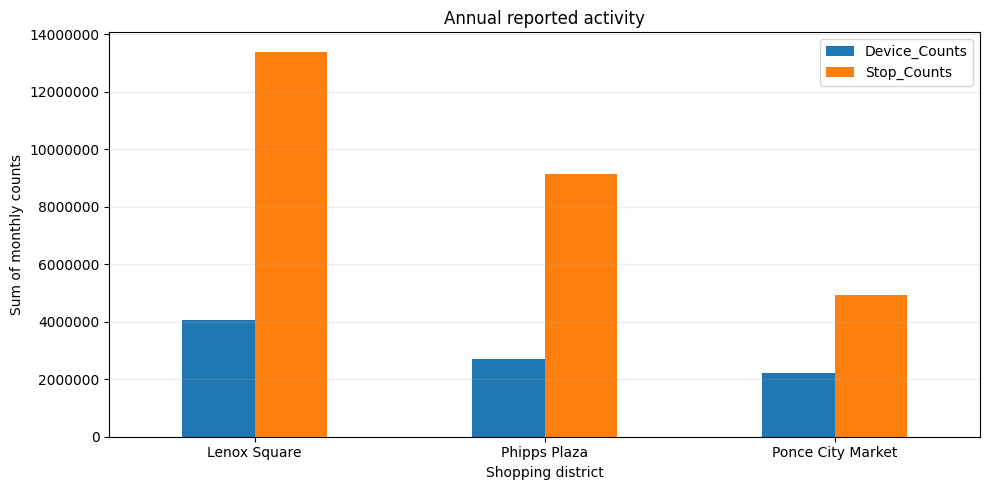

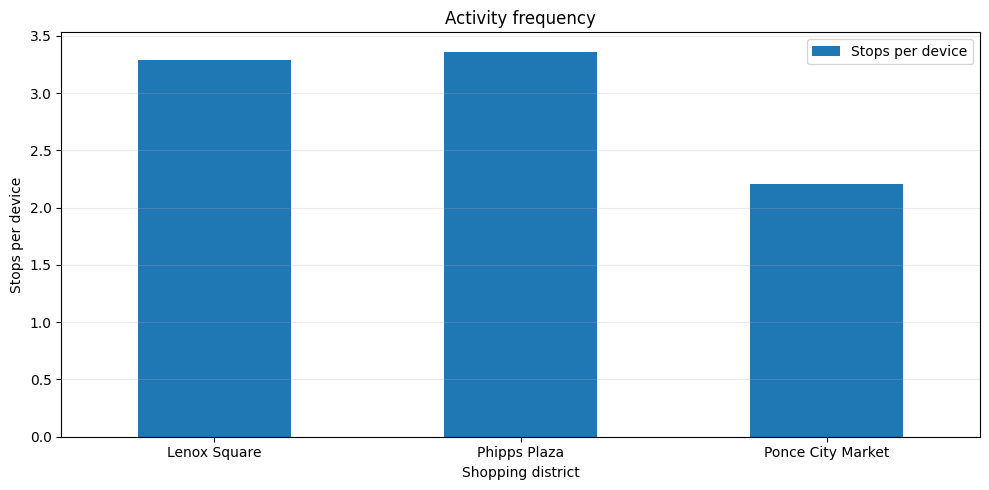

**Finding:** Lenox Square has the largest reported device activity. Phipps Plaza has the highest ratio of stops to devices.

In [3]:
annual=summary.groupby('Mall')[['Device_Counts','Stop_Counts']].sum().reindex(order)
annual['Stops per device']=annual.Stop_Counts/annual.Device_Counts
report(annual,'annual_activity')
chart(annual[['Device_Counts','Stop_Counts']], 'Annual reported activity','Sum of monthly counts')
chart(annual[['Stops per device']], 'Activity frequency','Stops per device')
display(Markdown(f"**Finding:** {annual.Device_Counts.idxmax()} has the largest reported device activity. {annual['Stops per device'].idxmax()} has the highest ratio of stops to devices."))

## 3. Monthly trends
Compare seasonal changes, without assuming that holidays caused the changes.

Mall,Lenox Square,Phipps Plaza,Ponce City Market
Month,,,
1,330235,222577,180812
2,334792,209679,207652
3,317805,215809,189347
4,300641,188792,180434
5,285100,187288,162479
6,265740,175137,151944
7,302347,211315,161197
8,291081,196641,163436
9,310951,210032,169290


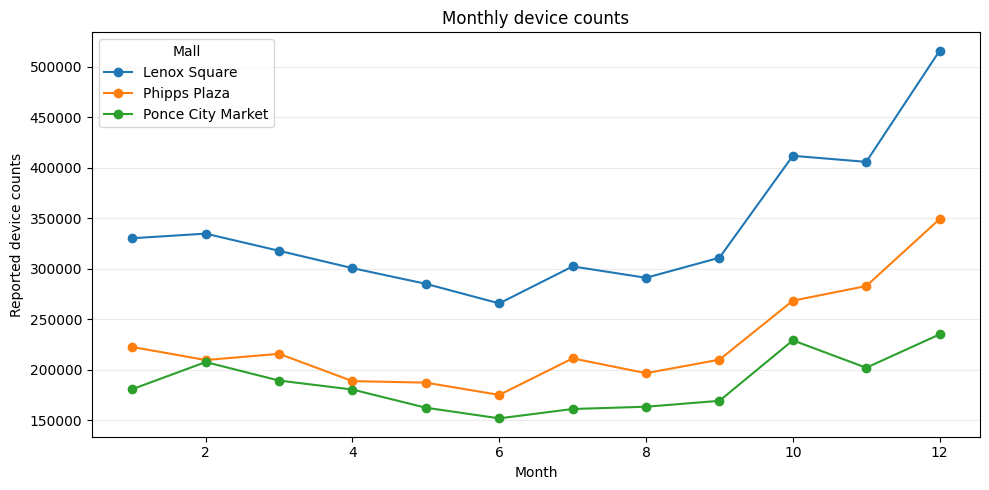

,June to December change (%)
Mall,
Lenox Square,94.124
Phipps Plaza,99.390
Ponce City Market,54.711


,Peak month
Mall,
Lenox Square,12
Phipps Plaza,12
Ponce City Market,12


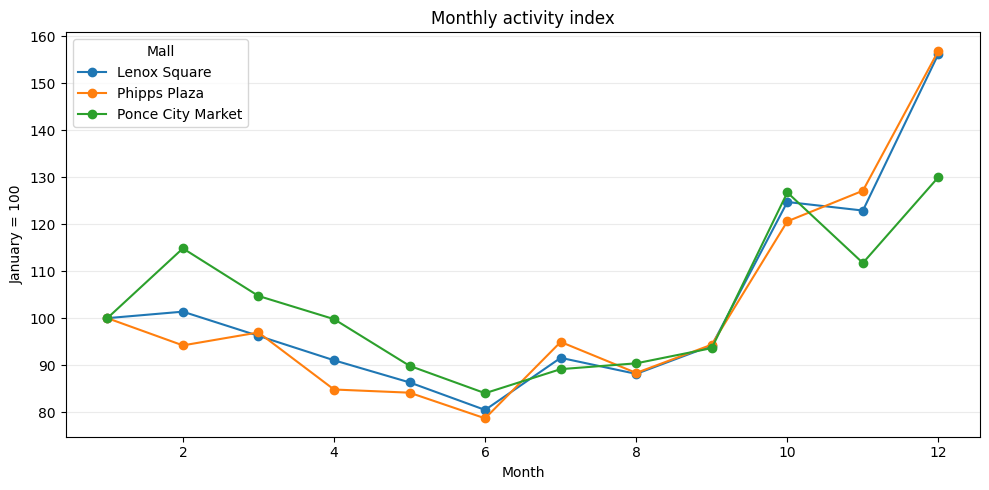

In [4]:
monthly=summary.pivot(index='Month',columns='Mall',values='Device_Counts')[order]
report(monthly,'monthly_devices')
chart(monthly,'Monthly device counts','Reported device counts','line')
change=(monthly.loc[12]/monthly.loc[6]-1)*100
report(change.to_frame('June to December change (%)'),'seasonal_change')
report(monthly.idxmax().to_frame('Peak month'),'peak_month')
chart(monthly.div(monthly.loc[1]).mul(100),'Monthly activity index','January = 100','line')

## 4. Where do reported devices come from?
Use only the All period to avoid double counting across overlapping weekday/weekend categories. Georgia CBG codes begin with 13.

,Unique_origins,Reported_counts,Georgia_counts,Georgia_share_pct,Reported_to_total_ratio_pct
Mall,,,,,
Lenox Square,7586,1545519,1366931,88.445,37.953
Phipps Plaza,6635,1242285,1124762,90.540,45.709
Ponce City Market,7028,1014793,910153,89.689,45.448


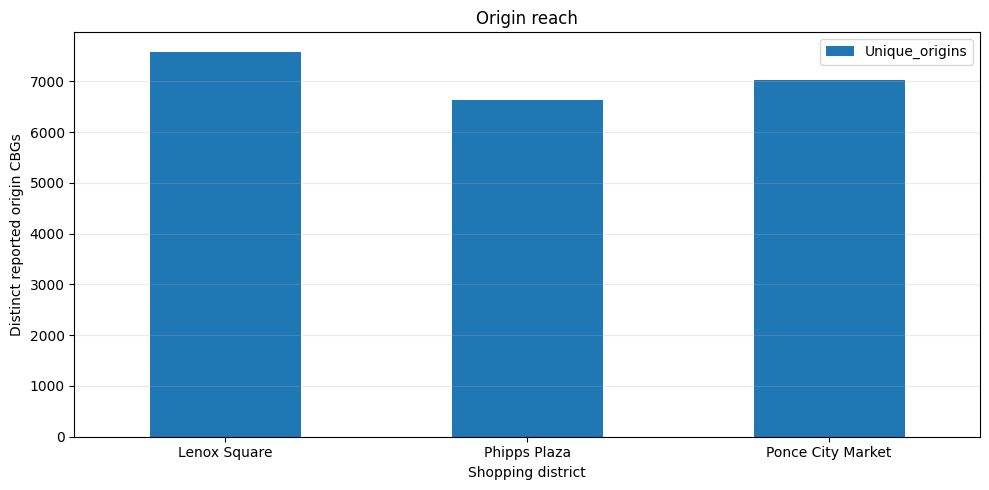

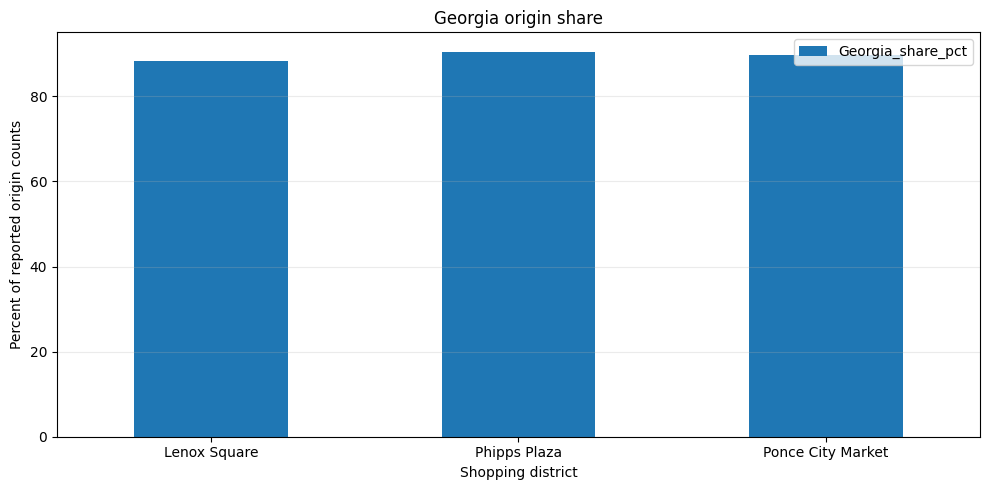

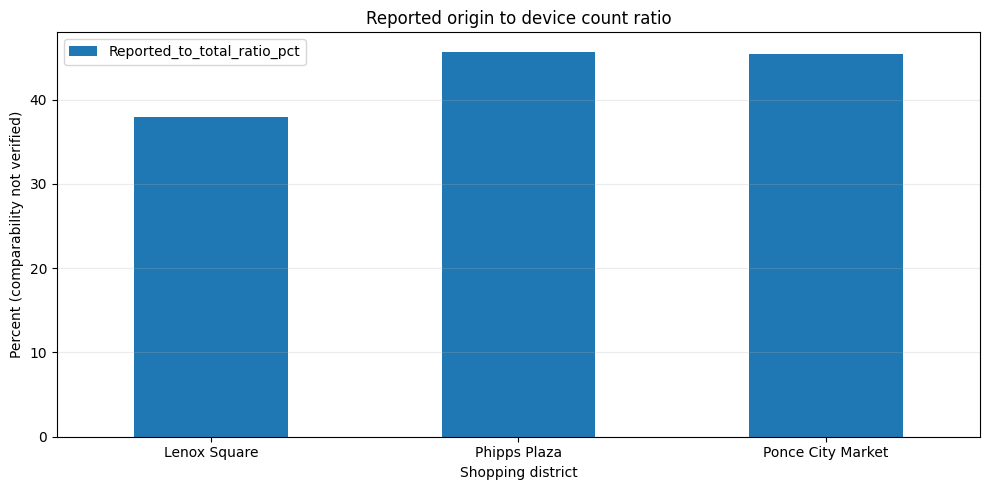

Month,1,2,3,4,5,6,7,8,9,10,11,12
Mall,,,,,,,,,,,,
Lenox Square,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
Phipps Plaza,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
Ponce City Market,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000


**Interpretation:** Each destination-month reports 2,000 origins. This suggests a possible reporting cap. Missing origins must not be treated as zero. The ratio above is not a verified coverage rate until the data dictionary establishes comparable counting rules.

In [5]:
orig=all_flows.groupby('Mall').agg(Unique_origins=('Origin_CBG','nunique'),Reported_counts=('Device_Count','sum')).reindex(order)
orig['Georgia_counts']=all_flows[all_flows.Origin_CBG.str.startswith('13')].groupby('Mall').Device_Count.sum()
orig['Georgia_share_pct']=100*orig.Georgia_counts/orig.Reported_counts
orig['Reported_to_total_ratio_pct']=100*orig.Reported_counts/annual.Device_Counts
report(orig,'origin_profile')
chart(orig[['Unique_origins']],'Origin reach','Distinct reported origin CBGs')
chart(orig[['Georgia_share_pct']],'Georgia origin share','Percent of reported origin counts')
chart(orig[['Reported_to_total_ratio_pct']],'Reported origin to device count ratio','Percent (comparability not verified)')
report(all_flows.groupby(['Mall','Month']).size().unstack(),'origins_per_month')
display(Markdown('**Interpretation:** Each destination-month reports 2,000 origins. This suggests a possible reporting cap. Missing origins must not be treated as zero. The ratio above is not a verified coverage rate until the data dictionary establishes comparable counting rules.'))

## 5. Weekday and weekend origin profiles
These categories may overlap; they are not additive and are not normalized by the number of weekdays or weekend days.

Device_Count  Georgia_counts  Georgia_share_pct
Mall              Period                                                  
Lenox Square      Weekday       1028673          937444             91.131
                  Weekend        716451          671228             93.688
Phipps Plaza      Weekday        860262          793555             92.246
                  Weekend        557817          509705             91.375
Ponce City Market Weekday        651015          598893             91.994
                  Weekend        525067          475447             90.550

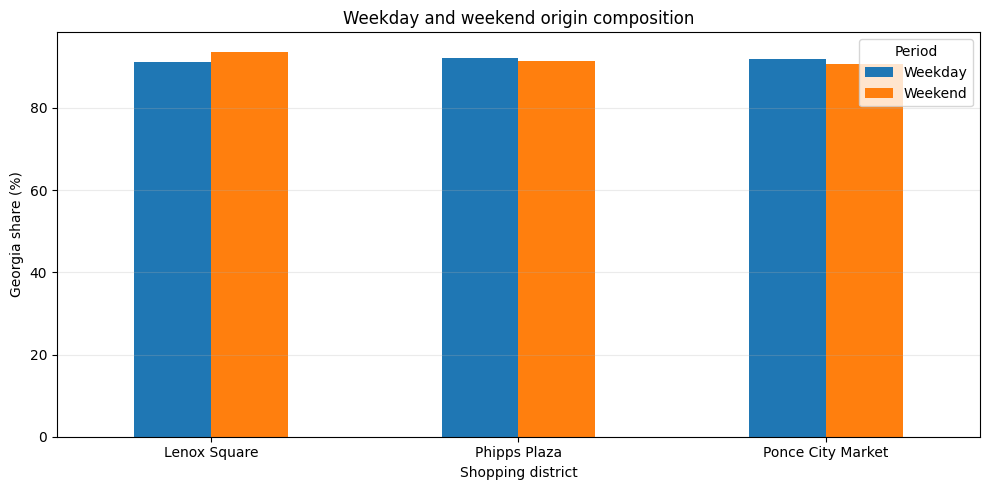

In [6]:
period=flows[flows.Period.isin(['Weekday','Weekend'])].copy()
period['Georgia_counts']=period.Device_Count.where(period.Origin_CBG.str.startswith('13'),0)
profile=period.groupby(['Mall','Period'])[['Device_Count','Georgia_counts']].sum()
profile['Georgia_share_pct']=100*profile.Georgia_counts/profile.Device_Count
report(profile,'weekday_weekend_profile')
chart(profile.Georgia_share_pct.unstack().reindex(order),'Weekday and weekend origin composition','Georgia share (%)')

## 6. Conclusions and next steps
- The three districts differ in overall reported activity, frequency of stops and seasonal patterns.
- These differences describe CBG activity, not necessarily shopping. Offices, homes and other businesses may contribute.
- Device counts are not verified unique persons or sales. Origin truncation, panel coverage and scaling require documentation.
- Existing 2024 ACS ZIP-level data and driving distances support the original accessibility analysis. For a CBG-level mobility model, collect ACS 2024 five-year CBG median household income (B19013), population (B01003), and matching geographic coordinates/boundaries. Optional controls include Gini (B19083), education (B15003) and poverty (B17001).
- Restrict to a predefined origin geography, document unmatched and suppressed origins, and estimate a PPML model of reported flows with distance and income-by-district-type interaction. Use origin-clustered uncertainty and acknowledge that comparisons involve only three destination districts. No causal or individual-income interpretation is warranted.

In [7]:
import shutil
archive=shutil.make_archive('Phase2_Foot_Traffic_Results','zip',output)
print('Results saved:',archive)

Results saved: /mnt/data/Phase2_Foot_Traffic_Results.zip
